# DAY 2 (part 2/2): Distance from Earth, phase angle and H
#### *Open Tools, Open Sky: Doing LSST Science with Public Rubin Data & LINCC Frameworks, UdeA, Medellín, October 13 2026*

Part 2 of 2. It needs `data/obs_elements_state_at_obstime.parquet`, written by `propagate_orbit_1_elements.ipynb`.

**Memory:** the ~8M-row files are never loaded whole: we read one row group at a time, only the columns we need, or only the rows of one object.

In [28]:
import gc
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import spiceypy
import pyarrow as pa
import pyarrow.compute as pc
import pyarrow.parquet as pq
from astroquery.jplhorizons import Horizons

data_dir = 'data/'
obs_path = data_dir + 'obs_elements_state.parquet'
state_cols = ['x', 'y', 'z', 'vx', 'vy', 'vz']

# Leap seconds, the Sun's GM (DE440) and the planetary ephemeris (Earth position)
spiceypy.furnsh('kernels/naif0012.tls')
spiceypy.furnsh('kernels/gm_de440.tpc')
spiceypy.furnsh('kernels/de440s.bsp')
mu_sun = spiceypy.bodvrd('SUN', 'GM', 1)[1][0]   # km^3/s^2
AU_KM = 149597870.7                              # km
C_KM_S = spiceypy.clight()                       # speed of light [km/s]

In [29]:
def propagate_orbit(gm, state, dt):
    """Propagate a state vector under two-body motion with spiceypy.prop2b.

    Parameters
    ----------
    gm : float
        Gravitational parameter of the central body (km^3/s^2).
    state : array_like, shape (6,)
        Initial state [x, y, z, vx, vy, vz] in km and km/s.
    dt : float or array_like
        Time(s) to propagate, in seconds. Negative values propagate backwards.

    Returns
    -------
    numpy.ndarray
        Shape (6,) if dt is a scalar, or (len(dt), 6) if dt is an array.
    """
    state = np.ascontiguousarray(state, dtype=float)   # prop2b needs a contiguous array (not a strided view)
    if np.isscalar(dt):
        return np.array(spiceypy.prop2b(gm, state, dt))
    return np.array([spiceypy.prop2b(gm, state, t) for t in dt])

In [30]:
def load_objects(designations, path, columns=None, batch_size=200_000):
    """Rows of the given objects from a big parquet file, without loading the whole file.

    The file is read in batches of `batch_size` rows; only the matching rows of each batch are kept.
    """
    if columns is not None and 'mpc_designation' not in columns:
        columns = list(columns) + ['mpc_designation']
    pf = pq.ParquetFile(path)
    wanted = pa.array(list(designations), type=pa.string())
    parts = []
    for batch in pf.iter_batches(batch_size=batch_size, columns=columns):
        mask = pc.is_in(batch['mpc_designation'].cast(pa.string()), value_set=wanted)
        if pc.any(mask).as_py():
            parts.append(batch.filter(mask))
    if not parts:
        return pd.DataFrame(columns=columns)
    return pa.Table.from_batches(parts).to_pandas()


### (162) Laurentia, the test object

Same as in part 1: its observations, observation times as ET, and the state at the MPC epoch.

In [31]:
obj_test_2 = load_objects(['(162) Laurentia'], obs_path,
                          columns=['obstime', 'mag', 'mpc_H', 'epoch_et'] + state_cols)
obj_test_2 = obj_test_2.sort_values('obstime').reset_index(drop=True)
obj_test_2['obs_et'] = [spiceypy.str2et(t.strftime('%Y-%m-%d %H:%M:%S.%f UTC')) for t in obj_test_2['obstime']]
epoch_et = obj_test_2['epoch_et'].iloc[0]          # MPC epoch of the elements (same for every row)
state0 = obj_test_2[state_cols].iloc[0].to_numpy(dtype=float)
print(len(obj_test_2), 'observations of (162) Laurentia')

12 observations of (162) Laurentia


## Earth position, distance from Earth and phase angle of (162) Laurentia

For each observation of Laurentia we compute, from our two-body propagation:

- the position of the Earth (geocenter) from the DE440 ephemeris (`kernels/de440s.bsp`), heliocentric ecliptic J2000, the same frame as the asteroid state;
- the distance Earth–asteroid $\Delta$;
- the phase angle $\alpha$ (Sun–asteroid–Earth angle).

Light takes ~20 min to travel from the asteroid to Earth, and the asteroid moves ~20,000 km in that time, so we correct for light time: the asteroid is taken at the time the light left it, $t - \Delta/c$ (iterated a few times).

We compare with JPL Horizons observer ephemerides for a geocentric observer (`500`), which give the same quantities (`delta`, `alpha`, and the heliocentric distance `r`).

In [32]:
obs_et_2 = obj_test_2['obs_et'].to_numpy()

# Earth (geocenter) seen from the Sun, ecliptic J2000 [km]
earth_pos = np.array([spiceypy.spkpos('EARTH', et, 'ECLIPJ2000', 'NONE', 'SUN')[0] for et in obs_et_2])


def observer_geometry(gm, state_epoch, epoch_et, obs_et, r_observer, n_iter=3):
    """Distance from the observer and phase angle, with light-time correction.

    Returns (r_sun [km], delta [km], phase angle [deg], light time [s]).
    """
    lt = 0.0
    for _ in range(n_iter):
        # Asteroid position when the light we receive at obs_et left it
        r_ast = propagate_orbit(gm, state_epoch, obs_et - lt - epoch_et)[:3]
        rho = r_ast - r_observer                 # observer -> asteroid
        lt = np.linalg.norm(rho) / C_KM_S
    # Phase angle: angle at the asteroid between the Sun and the observer
    to_sun, to_obs = -r_ast, -rho
    cos_alpha = np.dot(to_sun, to_obs) / (np.linalg.norm(to_sun) * np.linalg.norm(to_obs))
    return np.linalg.norm(r_ast), np.linalg.norm(rho), np.degrees(np.arccos(cos_alpha)), lt


geom = np.array([observer_geometry(mu_sun, state0, epoch_et, et, r_e)
                 for et, r_e in zip(obs_et_2, earth_pos)])
r_prop, delta_prop, alpha_prop, lt_prop = geom.T

In [33]:
# JPL Horizons, geocentric observer. Observer-table epochs are JD UTC
jd_utc = obj_test_2['obstime'].map(lambda t: t.to_julian_date()).to_numpy()
hor_eph = Horizons(id='162', id_type='smallbody', location='500', epochs=jd_utc.tolist()).ephemerides().to_pandas()
hor_eph = hor_eph.sort_values('datetime_jd').reset_index(drop=True)    # same order as obj_test_2 (sorted by obstime)

# Earth position from Horizons (heliocentric, ecliptic J2000), epochs in JD TDB
hor_earth = Horizons(id='399', id_type=None, location='500@10',
                     epochs=(2451545.0 + obs_et_2 / 86400).tolist()).vectors(refplane='ecliptic').to_pandas()
hor_earth = hor_earth.sort_values('datetime_jd').reset_index(drop=True)
earth_hor_km = hor_earth[['x', 'y', 'z']].to_numpy() * AU_KM

geometry_comparison = pd.DataFrame({
    'obstime (UTC)': obj_test_2['obstime'].dt.strftime('%Y-%m-%d %H:%M:%S').to_numpy(),
    'Earth: |SPICE - Horizons| [km]': np.linalg.norm(earth_pos - earth_hor_km, axis=1),
    'r prop [AU]': r_prop / AU_KM,
    'r hor [AU]': hor_eph['r'],
    'delta prop [AU]': delta_prop / AU_KM,
    'delta hor [AU]': hor_eph['delta'],
    'delta diff [km]': delta_prop - hor_eph['delta'] * AU_KM,
    'delta diff [%]': 100 * (delta_prop / AU_KM - hor_eph['delta']) / hor_eph['delta'],
    'alpha prop [deg]': alpha_prop,
    'alpha hor [deg]': hor_eph['alpha'],
    'alpha diff [arcsec]': (alpha_prop - hor_eph['alpha']) * 3600,
})
geometry_comparison

,obstime (UTC),Earth: |SPICE - Horizons| [km],r prop [AU],r hor [AU],delta prop [AU],delta hor [AU],delta diff [km],delta diff [%],alpha prop [deg],alpha hor [deg],alpha diff [arcsec]
0,2025-09-03 08:46:25,0.000378,3.526750,3.526809,2.537838,2.537884,-6822.476513,-0.001797,3.805908,3.8118,-21.212201
1,2025-09-03 08:47:04,0.000471,3.526750,3.526809,2.537837,2.537883,-6822.506752,-0.001797,3.805775,3.8117,-21.329209
2,2025-09-03 08:49:04,0.000533,3.526749,3.526808,2.537832,2.537878,-6822.598001,-0.001797,3.805376,3.8113,-21.326484
3,2025-09-03 08:49:44,0.000152,3.526749,3.526808,2.537831,2.537876,-6822.628159,-0.001797,3.805244,3.8112,-21.443288
4,2025-09-03 08:51:43,0.000168,3.526748,3.526807,2.537826,2.537872,-6822.719541,-0.001797,3.804844,3.8108,-21.440479
5,2025-09-03 08:55:02,0.000362,3.526747,3.526806,2.537818,2.537864,-6822.871142,-0.001797,3.804180,3.8101,-21.311326
6,2025-09-03 08:57:42,0.000463,3.526746,3.526805,2.537812,2.537858,-6822.992841,-0.001797,3.803648,3.8096,-21.427783
7,2025-11-17 02:10:12,0.000410,3.472590,3.472602,3.018385,3.018430,-6671.399097,-0.001477,15.592032,15.5876,15.953873
8,2025-11-17 03:46:59,0.000536,3.472531,3.472543,3.019282,3.019326,-6666.592525,-0.001476,15.598361,15.5939,16.057840
9,2025-11-17 03:50:33,0.000486,3.472529,3.472541,3.019315,3.019359,-6666.415257,-0.001476,15.598593,15.5941,16.176409


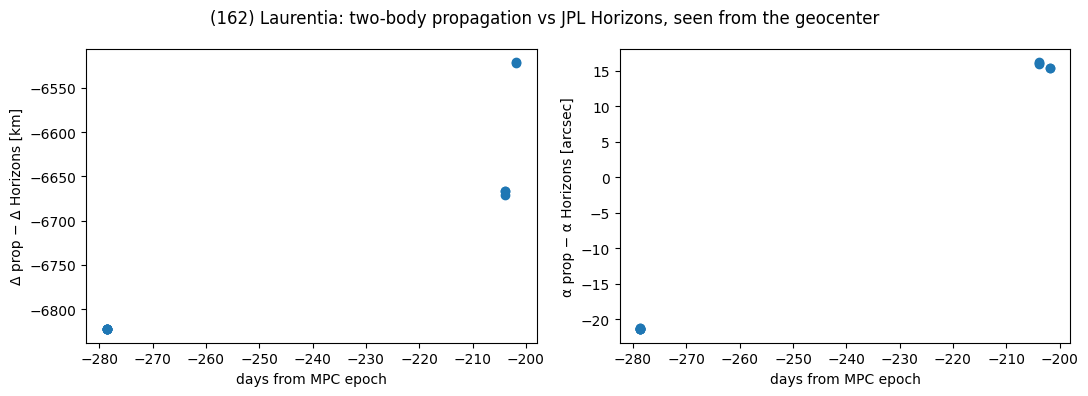

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
days = (obs_et_2 - epoch_et) / 86400
axes[0].plot(days, geometry_comparison['delta diff [km]'], 'o')
axes[0].set_xlabel('days from MPC epoch')
axes[0].set_ylabel('Δ prop − Δ Horizons [km]')
axes[1].plot(days, geometry_comparison['alpha diff [arcsec]'], 'o')
axes[1].set_xlabel('days from MPC epoch')
axes[1].set_ylabel('α prop − α Horizons [arcsec]')
fig.suptitle('(162) Laurentia: two-body propagation vs JPL Horizons, seen from the geocenter')
fig.tight_layout()
plt.show()

**Reading the results**

- Earth: SPICE (DE440) and Horizons agree to better than 1 m, so the observer position is not a source of error.
- Distance from Earth: the two-body $\Delta$ is ~6,500–6,800 km shorter than Horizons, i.e. ~0.002% of $\Delta$. This is much less than the ~18,000–34,000 km 3D position error found above: most of that error is across the line of sight, not along it.
- Phase angle: differences of ~15–21 arcsec (~0.006°), negligible for photometry (phase curves are sensitive at the ~0.1° level).

## Distance from Earth and phase angle for every observation

We add the distance from Earth (geocenter) and the phase angle to the orbital elements of every observation, and save the result to `data/obs_elements_geometry_at_obstime.parquet`.

- The elements and the asteroid state at each observation time are read from `data/obs_elements_state_at_obstime.parquet`, one row group (500k rows) at a time.
- Light-time correction: instead of propagating again with `prop2b`, the asteroid position when the light left it is approximated as `r(t - lt) = r(t) - v(t) * lt` (iterated). Over ~20 min of light time the error of this linear step is below 1 km.
- The Earth position only depends on the time, so it is computed once per distinct observation time (~47k) with SPICE.

In [35]:
def earth_geometry(state, obs_et, n_iter=3):
    """Geocentric distance and phase angle of many asteroids at once, with light-time correction.

    state : (n, 6) heliocentric ecliptic J2000 state at the observation time [km, km/s]
    obs_et : (n,) observation times [TDB seconds past J2000]
    Returns delta [AU] and phase angle [deg].
    """
    # Earth position once per distinct time
    et_unique, inverse = np.unique(obs_et, return_inverse=True)
    earth_unique = np.array([spiceypy.spkpos('EARTH', et, 'ECLIPJ2000', 'NONE', 'SUN')[0] for et in et_unique])
    r_earth = earth_unique[inverse]

    r_ast, v_ast = state[:, :3], state[:, 3:]
    lt = np.zeros(len(state))
    for _ in range(n_iter):
        r_emit = r_ast - v_ast * lt[:, None]        # asteroid when the light left it
        rho = r_emit - r_earth                      # Earth -> asteroid
        dist = np.linalg.norm(rho, axis=1)
        lt = dist / C_KM_S

    # Phase angle: angle at the asteroid between the directions to the Sun (-r_emit) and to Earth (-rho)
    cos_alpha = np.einsum('ij,ij->i', r_emit, rho) / (np.linalg.norm(r_emit, axis=1) * dist)
    alpha = np.degrees(np.arccos(np.clip(cos_alpha, -1, 1)))
    return dist / AU_KM, alpha


# Check against the exact light-time calculation done above for Laurentia
laurentia_state = np.array([propagate_orbit(mu_sun, state0, et - epoch_et) for et in obs_et_2])
delta_lin, alpha_lin = earth_geometry(laurentia_state, obs_et_2)
print('max |delta difference| [km]:', np.abs(delta_lin * AU_KM - delta_prop).max())
print('max |alpha difference| [arcsec]:', np.abs(alpha_lin - alpha_prop).max() * 3600)

max |delta difference| [km]: 0.5473074913024902
max |alpha difference| [arcsec]: 6.999299060339581e-05


In [36]:
from parquet_docs import describe

elements_states_path = data_dir + 'obs_elements_state_at_obstime.parquet'
out_geometry = data_dir + 'obs_elements_geometry_at_obstime.parquet'

id_cols = ['obstime', 'mpc_row', 'mpc_designation', 'n_provids', 'obs_et', 'dt_from_epoch_days']
element_cols = ['a', 'e', 'q', 'incl', 'node', 'peri', 'M']
elements_states_file = pq.ParquetFile(elements_states_path)

writer = None
start = time.time()
for i in range(elements_states_file.metadata.num_row_groups):
    elements = elements_states_file.read_row_group(i, columns=id_cols + element_cols)
    states = elements_states_file.read_row_group(i, columns=['obs_et'] + state_cols)

    state = np.column_stack([states[c].to_numpy() for c in state_cols])
    delta, alpha = earth_geometry(state, states['obs_et'].to_numpy())
    table = elements.append_column('delta', pa.array(delta)).append_column('phase_angle', pa.array(alpha))
    table = describe(table, out_geometry)            # description of each column, saved in the file

    if writer is None:
        writer = pq.ParquetWriter(out_geometry, table.schema)
    writer.write_table(table)
    print(f'row group {i + 1}/{elements_states_file.metadata.num_row_groups}  ({time.time() - start:.0f} s)')
writer.close()
del elements, states, state, table
gc.collect()

row group 1/17  (1 s)
row group 2/17  (1 s)
row group 3/17  (2 s)
row group 4/17  (3 s)
row group 5/17  (4 s)
row group 6/17  (4 s)
row group 7/17  (5 s)
row group 8/17  (6 s)
row group 9/17  (7 s)
row group 10/17  (7 s)
row group 11/17  (8 s)
row group 12/17  (9 s)
row group 13/17  (10 s)
row group 14/17  (10 s)
row group 15/17  (11 s)
row group 16/17  (12 s)
row group 17/17  (12 s)


10672

In [37]:
elements_states_path = data_dir + 'obs_elements_state_at_obstime.parquet'
out_geometry = data_dir + 'obs_elements_geometry_at_obstime.parquet'

geometry_file = pq.ParquetFile(out_geometry)
print(f"{geometry_file.metadata.num_rows:,} rows in {out_geometry}")
print(geometry_file.schema_arrow.names)

# delta [AU] and phase_angle [deg] for Laurentia, next to the Horizons values from above
# Only Laurentia's rows (reading the whole file gives MemoryError)
laurentia = pd.read_parquet(out_geometry, filters=[('mpc_designation', '==', '(162) Laurentia')]).sort_values('obstime')

8,021,265 rows in data/obs_elements_geometry_at_obstime.parquet
['obstime', 'mpc_row', 'mpc_designation', 'n_provids', 'obs_et', 'dt_from_epoch_days', 'a', 'e', 'q', 'incl', 'node', 'peri', 'M', 'delta', 'phase_angle']


In [38]:
laurentia.head(20)

,obstime,mpc_row,mpc_designation,n_provids,obs_et,dt_from_epoch_days,a,e,q,incl,node,peri,M,delta,phase_angle
5,2025-09-03 08:46:25.045,161,(162) Laurentia,1,8.101613e+08,-278.633632,3.013649,0.183172,2.461634,6.09272,35.4191,115.69265,205.515336,2.537838,3.805908
6,2025-09-03 08:47:04.756,161,(162) Laurentia,1,8.101613e+08,-278.633172,3.013649,0.183172,2.461634,6.09272,35.4191,115.69265,205.515423,2.537837,3.805775
2,2025-09-03 08:49:04.411,161,(162) Laurentia,1,8.101614e+08,-278.631787,3.013649,0.183172,2.461634,6.09272,35.4191,115.69265,205.515684,2.537832,3.805376
0,2025-09-03 08:49:44.106,161,(162) Laurentia,1,8.101615e+08,-278.631328,3.013649,0.183172,2.461634,6.09272,35.4191,115.69265,205.515770,2.537831,3.805244
4,2025-09-03 08:51:43.757,161,(162) Laurentia,1,8.101616e+08,-278.629943,3.013649,0.183172,2.461634,6.09272,35.4191,115.69265,205.516031,2.537826,3.804844
3,2025-09-03 08:55:02.808,161,(162) Laurentia,1,8.101618e+08,-278.627639,3.013649,0.183172,2.461634,6.09272,35.4191,115.69265,205.516465,2.537818,3.804180
1,2025-09-03 08:57:42.368,161,(162) Laurentia,1,8.101619e+08,-278.625792,3.013649,0.183172,2.461634,6.09272,35.4191,115.69265,205.516813,2.537812,3.803648
7,2025-11-17 02:10:12.787,161,(162) Laurentia,1,8.166175e+08,-203.908773,3.013649,0.183172,2.461634,6.09272,35.4191,115.69265,219.592989,3.018385,15.592032
8,2025-11-17 03:46:59.261,161,(162) Laurentia,1,8.166233e+08,-203.841569,3.013649,0.183172,2.461634,6.09272,35.4191,115.69265,219.605650,3.019282,15.598360
9,2025-11-17 03:50:33.350,161,(162) Laurentia,1,8.166235e+08,-203.839091,3.013649,0.183172,2.461634,6.09272,35.4191,115.69265,219.606117,3.019315,15.598593


## Absolute magnitude H of (162) Laurentia

With the HG system (Bowell et al. 1989), the apparent V magnitude is

$$V = H + 5\log_{10}(r\,\Delta) - 2.5\log_{10}\left[(1-G)\,\Phi_1(\alpha) + G\,\Phi_2(\alpha)\right]$$

$$\Phi_1(\alpha) = \exp\left[-3.33\,(\tan\tfrac{\alpha}{2})^{0.63}\right] \qquad \Phi_2(\alpha) = \exp\left[-1.87\,(\tan\tfrac{\alpha}{2})^{1.22}\right]$$

with $r$ and $\Delta$ in AU. Solving for $H$ for each observation, with $G = 0.15$ and the $r$, $\Delta$, $\alpha$ computed above (two-body propagation, light-time corrected, geocentric):

$$H = V - 5\log_{10}(r\,\Delta) + 2.5\log_{10}\left[(1-G)\,\Phi_1(\alpha) + G\,\Phi_2(\alpha)\right]$$

**Magnitudes.** We use the `mag` column of `data_mpc` (Rubin) as the apparent magnitude: $V = $ `mag`.

In [39]:
# Rubin magnitudes of Laurentia: the 'mag' column of data_mpc (obj_test_2 is a slice of it, sorted by obstime,
# the same order as r_prop, delta_prop and alpha_prop). We take V = mag
laurentia_phot = obj_test_2[['obstime', 'mag']].reset_index(drop=True)
laurentia_phot['V'] = laurentia_phot['mag'].astype(float)

In [40]:
def absolute_magnitude(V, r_au, delta_au, alpha_deg, G=0.15):
    """H from the apparent V magnitude with the HG phase function (Bowell et al. 1989)."""
    tan_half = np.tan(np.radians(alpha_deg) / 2)
    phi1 = np.exp(-3.33 * tan_half**0.63)
    phi2 = np.exp(-1.87 * tan_half**1.22)
    return V - 5 * np.log10(r_au * delta_au) + 2.5 * np.log10((1 - G) * phi1 + G * phi2)


laurentia_phot['r [AU]'] = r_prop / AU_KM
laurentia_phot['delta [AU]'] = delta_prop / AU_KM
laurentia_phot['alpha [deg]'] = alpha_prop
laurentia_phot['H'] = absolute_magnitude(laurentia_phot['V'], laurentia_phot['r [AU]'],
                                         laurentia_phot['delta [AU]'], laurentia_phot['alpha [deg]'])
# Horizons predicted V at the same times (from the geocentric ephemeris queried above)
laurentia_phot['V Horizons'] = hor_eph['V'].to_numpy()
laurentia_phot['V - V Horizons'] = laurentia_phot['V'] - laurentia_phot['V Horizons']
laurentia_phot

,obstime,mag,V,r [AU],delta [AU],alpha [deg],H,V Horizons,V - V Horizons
0,2025-09-03 08:46:25.045,13.541,13.541,3.526750,2.537838,3.805908,8.426955,14.204,-0.663
1,2025-09-03 08:47:04.756,13.545,13.545,3.526750,2.537837,3.805775,8.430964,14.204,-0.659
2,2025-09-03 08:49:04.411,13.589,13.589,3.526749,2.537832,3.805376,8.474992,14.204,-0.615
3,2025-09-03 08:49:44.106,13.541,13.541,3.526749,2.537831,3.805244,8.427001,14.204,-0.663
4,2025-09-03 08:51:43.757,13.557,13.557,3.526748,2.537826,3.804844,8.443029,14.204,-0.647
5,2025-09-03 08:55:02.808,13.551,13.551,3.526747,2.537818,3.804180,8.437075,14.204,-0.653
6,2025-09-03 08:57:42.368,13.555,13.555,3.526746,2.537812,3.803648,8.441111,14.204,-0.649
7,2025-11-17 02:10:12.787,15.181,15.181,3.472590,3.018385,15.592032,9.224808,15.046,0.135
8,2025-11-17 03:46:59.261,14.578,14.578,3.472531,3.019282,15.598361,8.620983,15.047,-0.469
9,2025-11-17 03:50:33.350,14.561,14.561,3.472529,3.019315,15.598593,8.603952,15.047,-0.486


In [41]:
H_jpl = hor_eph['H'].iloc[0]                      # H used by JPL (Horizons)
H_mpc = obj_test_2['mpc_H'].iloc[0]                # H in MPCORB

H_rubin = laurentia_phot['H'].mean()
H_err = laurentia_phot['H'].std() / np.sqrt(len(laurentia_phot))
print(f"H from Rubin:        {H_rubin:.2f} +/- {H_err:.2f}  (std of single observations {laurentia_phot['H'].std():.2f})")
print(f"H from JPL Horizons: {H_jpl:.2f}   difference Rubin - JPL = {H_rubin - H_jpl:+.2f} mag")
print(f"H from MPCORB:       {H_mpc:.2f}   difference Rubin - MPC = {H_rubin - H_mpc:+.2f} mag")

# H per night
laurentia_phot.groupby(laurentia_phot['obstime'].dt.date)['H'].agg(['mean', 'std', 'count']).assign(
    **{'mean - H_JPL': lambda d: d['mean'] - H_jpl})

H from Rubin:        8.64 +/- 0.09  (std of single observations 0.30)
H from JPL Horizons: 9.09   difference Rubin - JPL = -0.45 mag
H from MPCORB:       9.08   difference Rubin - MPC = -0.44 mag


,mean,std,count,mean - H_JPL
obstime,,,,
2025-09-03,8.440161,0.016653,7,-0.649839
2025-11-17,8.816581,0.353638,3,-0.273419
2025-11-19,9.058189,0.040326,2,-0.031811


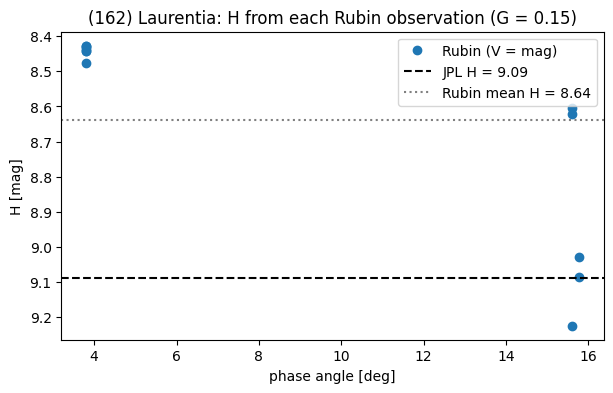

In [42]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(laurentia_phot['alpha [deg]'], laurentia_phot['H'], 'o', label='Rubin (V = mag)')
ax.axhline(H_jpl, color='k', ls='--', label=f'JPL H = {H_jpl:.2f}')
ax.axhline(H_rubin, color='gray', ls=':', label=f'Rubin mean H = {H_rubin:.2f}')
ax.set_xlabel('phase angle [deg]')
ax.set_ylabel('H [mag]')
ax.invert_yaxis()
ax.set_title('(162) Laurentia: H from each Rubin observation (G = 0.15)')
ax.legend()
plt.show()

**Reading the results**

- With $V$ = `mag`, Rubin gives $H = 8.64 \pm 0.09$, 0.45 mag brighter than JPL ($H = 9.09$) and MPCORB ($H = 9.08$).
- The single observations scatter by 0.30 mag, and the offset from JPL changes from night to night: −0.65 mag on 2025-09-03, −0.27 on 2025-11-17 and −0.03 on 2025-11-19. The column `V - V Horizons` shows the same pattern in the apparent magnitude.
- The geometry is not the cause: $r$, $\Delta$ and $\alpha$ agree with Horizons to ~0.002% and ~20 arcsec, which changes $H$ by less than 0.001 mag.
- The differences come from the photometry and the model:
  - **Band**: Rubin `mag` is measured in an LSST band (z on 2025-09-03, g and i in November), not in V. Asteroids are brighter in i and z than in V, which fits the large offset of the 2025-09-03 (z) night and of the two i observations on 2025-11-17.
  - **Rotation**: a single night samples one part of the lightcurve; amplitudes of 0.1–0.3 mag are typical.
  - **Phase function**: $G = 0.15$ is a default. The 2025-09-03 observations are at $\alpha \approx 3.8°$, where the opposition effect is strong and a wrong $G$ matters most.

## Final file: orbital elements, distance from Earth, phase angle and H for every observation

For every observation we compute $H$ with the HG formula above ($G = 0.15$, $V$ = `mag`) and save everything to `data/obs_final_elements_geometry_H.parquet`:

- identification: `obstime`, `mpc_row`, `mpc_designation`, `permid` (number), `provid` (provisional designation), `n_provids` (number of Rubin provids of the object: 2 = reported by Rubin as two objects), `obs_et`, `dt_from_epoch_days`
- osculating elements at the observation time: `a, e, q, incl, node, peri, M` [AU, deg]
- `r` (distance from the Sun) and `delta` (distance from Earth) [AU], `phase_angle` [deg], light-time corrected, geocentric
- `mag` (Rubin) and `H`

`r` is computed here from the state vectors, at the same light-time corrected position used for `delta` and `phase_angle`: $r = |\vec r(t) - \vec v(t)\,\Delta/c|$.

The geometry and elements/state-vector files have the same rows in the same order as `data/obs_state_vector.parquet` (checked below), so `mag`, `permid` and `provid` are taken row by row from that file. Rows without `mag` get `H` = NaN.

In [43]:
geometry_path = data_dir + 'obs_elements_geometry_at_obstime.parquet'
states_path = data_dir + 'obs_elements_state_at_obstime.parquet'
final_path = data_dir + 'obs_final_elements_geometry_H.parquet'

source_cols = ['obstime', 'mpc_row', 'permid', 'provid', 'mag']
source_file = pq.ParquetFile(obs_path)
geometry_file = pq.ParquetFile(geometry_path)
states_file = pq.ParquetFile(states_path)
assert geometry_file.metadata.num_rows == states_file.metadata.num_rows == source_file.metadata.num_rows

# First row of each row group of the source file
source_starts = np.cumsum([0] + [source_file.metadata.row_group(k).num_rows
                                 for k in range(source_file.metadata.num_row_groups)])


def read_rows(start, stop):
    """Rows [start, stop) of the source file, reading only the row groups that contain them."""
    first = np.searchsorted(source_starts, start, side='right') - 1
    last = np.searchsorted(source_starts, stop, side='left') - 1
    groups = list(range(first, last + 1))
    table = source_file.read_row_groups(groups, columns=source_cols)
    return table.slice(start - source_starts[first], stop - start)


writer = None
offset = 0
start = time.time()
for i in range(geometry_file.metadata.num_row_groups):
    geometry = geometry_file.read_row_group(i)
    states = states_file.read_row_group(i, columns=['obs_et'] + state_cols)
    n = geometry.num_rows
    source = read_rows(offset, offset + n)       # Rubin magnitudes and designations of the same rows
    # Same rows in all files
    assert np.array_equal(geometry['obs_et'].to_numpy(), states['obs_et'].to_numpy())
    assert np.array_equal(geometry['obstime'].to_numpy(), source['obstime'].to_numpy())
    assert np.array_equal(geometry['mpc_row'].to_numpy(), source['mpc_row'].to_numpy())

    # Distance from the Sun at the light-time corrected position [AU]
    pos = np.column_stack([states[c].to_numpy() for c in ['x', 'y', 'z']])
    vel = np.column_stack([states[c].to_numpy() for c in ['vx', 'vy', 'vz']])
    delta = geometry['delta'].to_numpy()
    lt = delta * AU_KM / C_KM_S
    r_sun = np.linalg.norm(pos - vel * lt[:, None], axis=1) / AU_KM

    mag = source['mag'].to_numpy(zero_copy_only=False).astype(float)
    H = absolute_magnitude(mag, r_sun, delta, geometry['phase_angle'].to_numpy())

    table = (geometry.append_column('r', pa.array(r_sun))
                     .append_column('mag', pa.array(mag))
                     .append_column('permid', source['permid'])
                     .append_column('provid', source['provid'])
                     .append_column('H', pa.array(H)))
    # Column order: identification, elements, geometry, photometry
    table = table.select(['obstime', 'mpc_row', 'mpc_designation', 'permid', 'provid', 'n_provids', 'obs_et', 'dt_from_epoch_days',
                          'a', 'e', 'q', 'incl', 'node', 'peri', 'M',
                          'r', 'delta', 'phase_angle', 'mag', 'H'])
    table = describe(table, final_path)              # description of each column, saved in the file
    if writer is None:
        writer = pq.ParquetWriter(final_path, table.schema)
    writer.write_table(table)
    offset += n
    print(f'row group {i + 1}/{geometry_file.metadata.num_row_groups}  ({time.time() - start:.0f} s)')
writer.close()
del geometry, states, source, table, pos, vel
gc.collect()

row group 1/17  (1 s)
row group 2/17  (1 s)
row group 3/17  (2 s)
row group 4/17  (3 s)
row group 5/17  (4 s)
row group 6/17  (4 s)
row group 7/17  (5 s)
row group 8/17  (6 s)
row group 9/17  (7 s)
row group 10/17  (7 s)
row group 11/17  (8 s)
row group 12/17  (9 s)
row group 13/17  (10 s)
row group 14/17  (10 s)
row group 15/17  (11 s)
row group 16/17  (12 s)
row group 17/17  (12 s)


13508

In [44]:
geometry_path = data_dir + 'obs_elements_geometry_at_obstime.parquet'
states_path = data_dir + 'obs_elements_state_at_obstime.parquet'
final_path = data_dir + 'obs_final_elements_geometry_H.parquet'
final_file = pq.ParquetFile(final_path)
H_all = final_file.read(columns=['H'])['H'].to_numpy()
print(f"{final_file.metadata.num_rows:,} rows in {final_path}")
print(final_file.schema_arrow.names)
print(f"H computed for {np.isfinite(H_all).sum():,} observations ({np.isnan(H_all).sum()} without mag)")

# Check: Laurentia gives the same H as the calculation above
laurentia_final = pd.read_parquet(final_path, filters=[('mpc_designation', '==', '(162) Laurentia')]).sort_values('obstime')
print(f"Laurentia mean H: {laurentia_final['H'].mean():.2f} (above: {laurentia_phot['H'].mean():.2f}, JPL: {H_jpl:.2f})")
laurentia_final

8,021,265 rows in data/obs_final_elements_geometry_H.parquet
['obstime', 'mpc_row', 'mpc_designation', 'permid', 'provid', 'n_provids', 'obs_et', 'dt_from_epoch_days', 'a', 'e', 'q', 'incl', 'node', 'peri', 'M', 'r', 'delta', 'phase_angle', 'mag', 'H']
H computed for 8,021,263 observations (2 without mag)
Laurentia mean H: 8.64 (above: 8.64, JPL: 9.09)


,obstime,mpc_row,mpc_designation,permid,provid,n_provids,obs_et,dt_from_epoch_days,a,e,q,incl,node,peri,M,r,delta,phase_angle,mag,H
5,2025-09-03 08:46:25.045,161,(162) Laurentia,162,A876 HB,1,8.101613e+08,-278.633632,3.013649,0.183172,2.461634,6.09272,35.4191,115.69265,205.515336,3.526750,2.537838,3.805908,13.541,8.426955
6,2025-09-03 08:47:04.756,161,(162) Laurentia,162,A876 HB,1,8.101613e+08,-278.633172,3.013649,0.183172,2.461634,6.09272,35.4191,115.69265,205.515423,3.526750,2.537837,3.805775,13.545,8.430964
2,2025-09-03 08:49:04.411,161,(162) Laurentia,162,A876 HB,1,8.101614e+08,-278.631787,3.013649,0.183172,2.461634,6.09272,35.4191,115.69265,205.515684,3.526749,2.537832,3.805376,13.589,8.474992
0,2025-09-03 08:49:44.106,161,(162) Laurentia,162,A876 HB,1,8.101615e+08,-278.631328,3.013649,0.183172,2.461634,6.09272,35.4191,115.69265,205.515770,3.526749,2.537831,3.805244,13.541,8.427001
4,2025-09-03 08:51:43.757,161,(162) Laurentia,162,A876 HB,1,8.101616e+08,-278.629943,3.013649,0.183172,2.461634,6.09272,35.4191,115.69265,205.516031,3.526748,2.537826,3.804844,13.557,8.443029
3,2025-09-03 08:55:02.808,161,(162) Laurentia,162,A876 HB,1,8.101618e+08,-278.627639,3.013649,0.183172,2.461634,6.09272,35.4191,115.69265,205.516465,3.526747,2.537818,3.804180,13.551,8.437075
1,2025-09-03 08:57:42.368,161,(162) Laurentia,162,A876 HB,1,8.101619e+08,-278.625792,3.013649,0.183172,2.461634,6.09272,35.4191,115.69265,205.516813,3.526746,2.537812,3.803648,13.555,8.441111
7,2025-11-17 02:10:12.787,161,(162) Laurentia,162,A876 HB,1,8.166175e+08,-203.908773,3.013649,0.183172,2.461634,6.09272,35.4191,115.69265,219.592989,3.472590,3.018385,15.592032,15.181,9.224808
8,2025-11-17 03:46:59.261,161,(162) Laurentia,162,A876 HB,1,8.166233e+08,-203.841569,3.013649,0.183172,2.461634,6.09272,35.4191,115.69265,219.605650,3.472531,3.019282,15.598360,14.578,8.620983
9,2025-11-17 03:50:33.350,161,(162) Laurentia,162,A876 HB,1,8.166235e+08,-203.839091,3.013649,0.183172,2.461634,6.09272,35.4191,115.69265,219.606117,3.472529,3.019315,15.598593,14.561,8.603952


298,334 objects; Rubin H - MPCORB H: median -0.14 mag, 16-84% range [-0.29, +0.09]


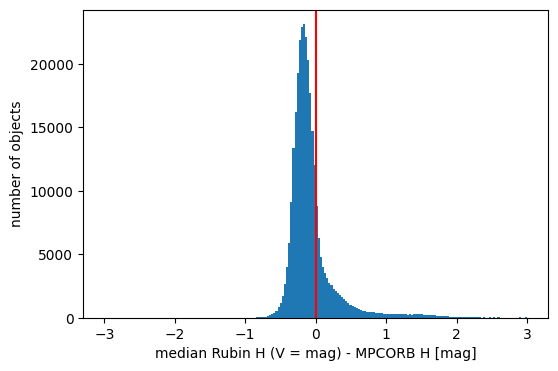

In [45]:
# One H per object: median over its observations, compared with the H in MPCORB.
# Only two numeric columns are read, so this fits in memory
H_obj = (pq.read_table(final_path, columns=['mpc_row', 'H']).to_pandas()
         .groupby('mpc_row')['H'].agg(['median', 'count']))
mpc_H = pq.read_table(obs_path, columns=['mpc_row', 'mpc_H']).to_pandas().drop_duplicates('mpc_row')
H_obj = H_obj.join(mpc_H.set_index('mpc_row')['mpc_H'].astype(float))
del mpc_H
diff = (H_obj['median'] - H_obj['mpc_H']).dropna()
print(f"{len(H_obj):,} objects; Rubin H - MPCORB H: median {diff.median():+.2f} mag, "
      f"16-84% range [{diff.quantile(0.16):+.2f}, {diff.quantile(0.84):+.2f}]")

fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(diff, bins=200, range=(-3, 3))
ax.axvline(0, color='red')
ax.set_xlabel('median Rubin H (V = mag) - MPCORB H [mag]')
ax.set_ylabel('number of objects')
plt.show()

In [46]:
import pandas as pd
data_dir = 'data/'
final_path = data_dir + 'obs_final_elements_geometry_H.parquet'

laurentia_final = pd.read_parquet(final_path, filters=[('mpc_designation', '==', '2025 HB67')]).sort_values('obstime')

In [47]:
laurentia_final

,obstime,mpc_row,mpc_designation,permid,provid,n_provids,obs_et,dt_from_epoch_days,a,e,q,incl,node,peri,M,r,delta,phase_angle,mag,H


In [48]:
# Description of the file and of each column (saved in the parquet schema; pandas does not show them)
from parquet_docs import column_descriptions
pd.set_option('display.max_colwidth', None)
column_descriptions(data_dir + 'obs_final_elements_geometry_H.parquet')

Final table, one row per Rubin detection with an MPC orbit: osculating elements, distances from the Sun and the Earth, phase angle, Rubin magnitude and absolute magnitude H. Written by propagate_orbit_2_geometry_H.ipynb.


,column,type,description
0,obstime,timestamp[us],"Time of the observation, UTC."
1,mpc_row,int64,"Row (0-based) of the object in MPCORB (data/mpcorb_extended.dat.gz) as read in exploration_data.ipynb. One value per object, like mpc_designation."
2,mpc_designation,string,"Designation of the object in the MPC orbit catalogue (MPCORB readable designation, e.g. '(1) Ceres', '(831800) 2009 WC150' or '2021 AQ'). It is the same for all the detections of an object, so use it to group detections by object: one object can have several provid (see n_provids). Null if the object was not found (comets, or permid and provid both null)."
3,permid,string,"Permanent number of the object (numbered minor planets, e.g. '831800'; comets e.g. '228P'), as reported with the detection. Null for unnumbered objects."
4,provid,string,"Provisional designation with which Rubin reported the detection (e.g. '2025 JQ7'). It is NOT a unique object id: the MPC may later link two provids to the same object (e.g. '2025 JQ7' and '2025 NF311' are both '2025 NF311'), so to group by object use mpc_designation. See n_provids."
5,n_provids,int64,"Number of different Rubin provids of the object (same mpc_designation) in the Rubin catalogue: 1 = one provid; 2 = Rubin reported the object as two separate objects, with two provids that the MPC later linked (e.g. '2025 JQ7' and '2025 NF311' are both '2025 NF311'); 0 = reported only by its number (permid). The list of provids of each object is in data/mpc_designations.csv. Null if mpc_designation is null."
6,obs_et,double,Time of the observation as ephemeris time [TDB seconds past J2000].
7,dt_from_epoch_days,double,Time from the epoch of the MPC elements to the observation [days] (negative = before).
8,a,double,Semimajor axis [AU]: osculating two-body heliocentric element at the observation time (null if e >= 1).
9,e,double,Eccentricity: osculating two-body heliocentric element at the observation time.
